# Chapter 1 - Random signals

# Part 2 - Random signals filtering


## By Ludovic Moreau

<div style="page-break-after: always;"></div>



## General concepts

In the following, we denote by $x(t)$ the input of a filter, and $y(t)$ its output, and $h(t)$ its transfer function. A random signal filter is characterized by the following quantities:

1. **Output's average**
\begin{align}
\mu_s(t) &= E\left[ y(t) \right]= E\left[ \int_{-\infty}^{\infty} h(\tau)x(t-\tau)d\tau \right] \\
&= \int_{-\infty}^{\infty}E\left[ h(\tau)x(t-\tau)\right]d\tau \\
&= \int_{-\infty}^{\infty} h(\tau) \mu_x(t-\tau) d\tau \\ 
\end{align}

        
         
  
<div style="margin: auto; width: fit-content;">
<div style="background-color: yellow; display: inline-block; padding: 5px;">
        \( \mu_s(t) = h(t) \circledast \mu_e(t) \)
    </div>
</div>
Remark: if the input signal is wide-sense stationary, then $\mu_s(t) = h(t) \circledast \mu_e(0)$



2. **Output's autocorrelation**
We consider two instants $t_1$ and $t_2$. The correlation between $y(t_1)$ and $y(t_2)$ is:
\begin{align}
C_{yy}(\tau) &= E\left[ y(t,R) y(t+\tau,R) \right] \\
             &= E\left[ \left( x(t) \circledast h(t) \right)\left( x(t+\tau) \circledast h(t+\tau,R) \right) \right] \\
             &= E\left[ x(t)x(t+\tau) \right]\circledast E\left[ h(t)h(t+\tau) \right]
\end{align}



- Remark 1: if the input signal is wide-sense stationary, then so is the output. 

- Remark 2: this simplificartion is possible because $x$ and $h$ are independent and thus uncorrelated, and because convolution and expectation can be swapped


3. **Output's Power Spectral Density**
We remind that, according to Wiener–Khinchin theorem, the PSD is the Fourier transform of the autocorrelation. Hence:

<div style="margin: auto; width: fit-content;">
<div style="background-color: yellow; display: inline-block; padding: 5px;">
        \( DSP_y(f) = |H(f)|^2 DSP_x(f) \)
    </div>
</div>

## Matched filter

A matched filter is a filter used to maximize the signal-to-noise ratio (SNR) for a known signal in the presence of noise. It's designed to optimally detect a specific signal, known as the "template" or "reference signal," within a larger input signal or dataset. The matched filter is designed to have a response that is maximized when the input signal matches the reference signal and minimized when there is no match.

Mathematically, the matched filter operation involves correlating the input signal with the time-reversed and conjugated version of the reference signal. This correlation operation effectively aligns the reference signal with the input signal and enhances the components that match the reference. 

## Derivation of the Matched filter

Assume a random signal made of a **known** signal, $s$, with power $P$, corrupted by some noise, $n$, such that:
\begin{equation}
x(t) = s(t) + n(t).
\end{equation}

We remind the definition of SNR:
\begin{equation}
\text{SNR} = \frac{P}{\sigma^2 },
\end{equation}
where $P$ is the power of $s$, and $\sigma^2$ is the variance of $n$.  

Our goal is to determine a filter which output, $y_{\text{MF}}$, maximizes this SNR at any instant $t_0$. We also remind that the output of a filter with transfer function $h$ is the convolution between the input signal and the transfer function. In the present case:
\begin{equation}
y_{\text{MF}} =  \int_{-\infty}^{\infty}h(u)x(t-u)du=\int_{-\infty}^{\infty}h(u)s(t-u)du+\int_{-\infty}^{\infty}h(u)n(t-u)du = y_s(t) + y_n(t).
\end{equation}

Note that $y_s$ can also be written in terms of its Fourier transform: 
\begin{equation} y_s(t)=\int_{-\infty}^{\infty} H(f).S(f)e^{2\text{i}\pi f t }df.
\end{equation}
The same cannot be done for $y_n$, because it is a random process. However, thanks to Wiener-Khintchin theorem, it can be expressed in terms of its Power Spectral Density (PSD):
\begin{equation} y_n(t)=\int_{-\infty}^{\infty} H(f)N(f)^{1/2}e^{2\text{i}\pi f t}df,
\end{equation}
where $N(f)$ is the PSD of the noise. 

Now we can express the SNR at the filter output at a given instant, $t_0$, such that:
\begin{equation} 
\text{SNR}|_{t=t_0}=\frac{|y_s(t_0)|^2}{E \left[ |y_n(t) |^2 \right]}.
\end{equation}

Remark: for the above equality to be true, we have assumed that the noise has weak sense stationarity the esperance of the noise is independent on $t$). 

This can be developped further:
\begin{equation} 
\text{SNR}|_{t=t_0}=\frac{\int_{-\infty}^{\infty}| H(f)S(f)e^{2\text{i}\pi f t_0}    |^2 df }{\int_{-\infty}^{\infty} |H(f)|^2N(f)e^{2\text{i}\pi f t}df}.
\end{equation}

Let us apply Cauchy–Schwarz inequality to the numerator, this equation becomes:
\begin{equation}
\text{SNR}|_{t=t_0} \leq \int_{-\infty}^{\infty} \frac{|H(f)|^2|S(f)|^2}{|H(f)|^2|N(f)|}df=\int_{-\infty}^{\infty} \frac{|S(f)|^2}{N(f)}df
\end{equation}


Linear algebra tells us that this inequality becomes an equality if $h$ and $s$ are colinear, such that:
\begin{equation}
H(f)=\alpha e^{2\text{i}\pi f t_0}\frac{S^*(f)}{N(f)},
\end{equation}

where $\alpha$ is an arbitrary constant, $e^{2\text{i}\pi f t_0}$ is a time delay to the detection time $t_0$, and where $*$ denotes the complex conjugate. Hence the filter defined in the above equation is the best linear filter for detecting a known signal in the presence of noise.

In the following, we further assume that $N(f)$ is constant. For example if $n$ represents white noise, then $N(f) = \sigma^2$, where $\sigma^2$ is the variance of the white noise. In that case, the transfer function of the filter can be taken as:
\begin{equation}
H(f)= e^{2\text{i}\pi f t_0}S^*(f).
\end{equation}

For a real-valued signal, $S^*(f) = S(-f)$, and the output of the filter writes
\begin{equation}
y_{\text{MF}}(t) =  \int_{-\infty}^{\infty} e^{2\text{i}\pi f t_0} S(-f)S(f) e^{2\text{i}\pi f t}df = \int_{-\infty}^{\infty} S(-f)S(f) e^{-2\text{i}\pi f (t-t_0)} df.
\end{equation}

Writing $S(f)$ in terms of the Fourier transform, the above equation becomes:
\begin{equation}
y_{\text{MF}}(t) =  \int_{-\infty}^{\infty} S(-f)e^{2\text{i}\pi f (t-t_0)} \left[\int_{-\infty}^{\infty} s(t')e^{-2\text{i}\pi f t'}dt'\right] df .
\end{equation}

The integrals can be swapped, leading to:
\begin{equation}
y_{\text{MF}}(t) =  \int_{-\infty}^{\infty}s(t') \left[\int_{-\infty}^{\infty} S(-f)e^{-2\text{i}\pi f t'}e^{2\text{i}\pi f (t-t_0)}df\right] dt'= \int_{-\infty}^{\infty}s(t') \left[\int_{-\infty}^{\infty} S(-f)e^{-2\text{i}\pi f (t'-t+t_0)}df\right] dt'.
\end{equation}
 
We recognize that the term in square brackets is an inverse Fourier transform equal to $s(t'-t+t_0)$, thus
\begin{equation}
y_{\text{MF}}(t) =  \int_{-\infty}^{\infty}s(t')s(t'-t+t_0) dt'.
\end{equation}

With the change of variable $\tau = t-t_0$, this can be written as:
\begin{equation}
y_{\text{MF}}(\tau) =  \int_{-\infty}^{\infty} s(t)s(t-\tau)dt,
\end{equation}
and we see that the matched filter simply acts as a correlator whose output at time $t_0$ is C_{ss}(0), which is also the energy of $s$. In the presence of noise $n(t)$ in our measurement $x(t)$, the matched filter acts as a cross-correlation between the known (broad-cast) signal s(t) and the measurement x(t):
\begin{equation}
y_{\text{MF}}(t) =  \int_{-\infty}^{\infty} x(\tau)s(\tau-t)d\tau = x(t) \circledast s(-t).
\end{equation}
It will peak at the time in the measurement at which the known signal occurs. This is equivalent to a convolution of the measurement against a time-reversed (and conjugated if $s(t)$ is complex) version of the known signal $s(t)$.






### The matched filter in a nutshell for practical implementation

1. **Cross-Correlation:**
We want to design a matched filter to maximize the correlation between the received signal $x(t)$ and the known signal $s(t)$. The cross-correlation of $x(t)$ with $s(t)$ is given by:
$[C_{xs}(\tau) = \int_{-\infty}^{\infty} x(t)s^*(t-\tau) \, dt$]

2. **Optimal Matched Filter:**
The matched filter output $y_{\text{MF}}(t)$ is obtained by passing the received signal $x(t)$ through a filter with impulse response $h_{\text{MF}}(t)$. The filter's impulse response is chosen to be the time-reversed and conjugated version of the known signal $s(t)$:
$h_{\text{MF}}(t) = s^*(-t)$

3. **Output of the Matched Filter:**
The output of the matched filter is given by:

$y_{\text{MF}}(t) = \int_{-\infty}^{\infty} x(\tau)h_{\text{MF}}(t-\tau) \, d\tau$ 

$y_{\text{MF}}(t) = \int_{-\infty}^{\infty} [s(\tau) + n(\tau)] s^*(t-\tau) \, d\tau$

4. **Simplifying the Expression:**
$y_{\text{MF}}(t) = \int_{-\infty}^{\infty} s(\tau)s^*(t-\tau) \, d\tau + \int_{-\infty}^{\infty} n(\tau)s^*(t-\tau) \, d\tau$

The first term on the right side represents the correlation of the known signal $s(t)$ with itself and will result in a maximum response at the true time alignment. The second term represents the correlation of the noise $n(t)$ with the matched filter's impulse response $s^*(-t)$, which will ideally result in a low value due to the noise being uncorrelated with the signal.


### Example 

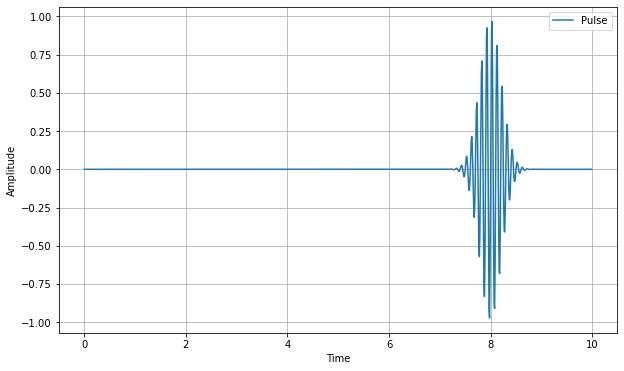

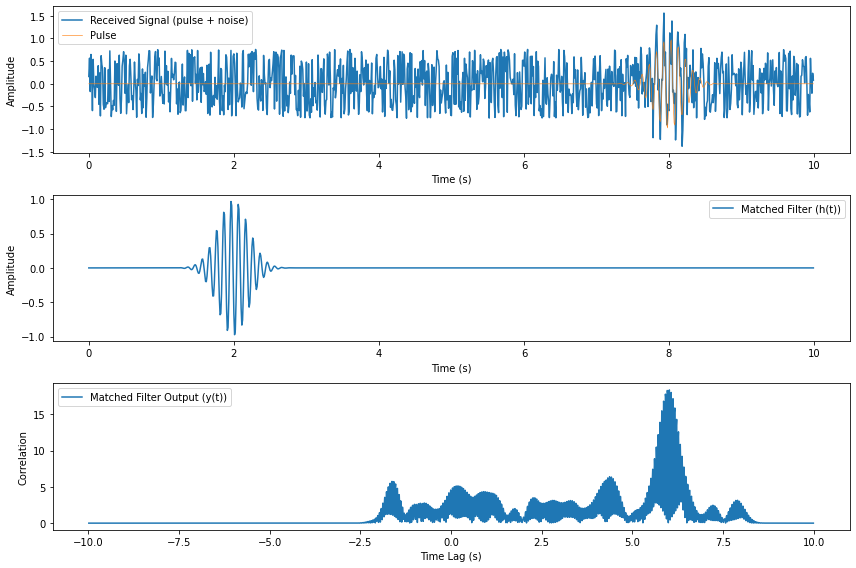

Time of maximum output: 6.0200000000000005 seconds, i.e. the time lag between the centre of the original signal, and the centre of the filter's impulse response


In [6]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
fc = 10.0  # Center frequency
T = 1.0  # Width of the envelope
t0 = 8  # Time delay for the envelope
SNR = -10.0  # Signal-to-noise ratio in dB
x = 1.0  # Position
fe = 10*fc


# Time vector
t = np.arange(0, 10, 1 / fe)

# Angular frequency and Gaussian envelope
omega = 2 * np.pi * fc
sigma = T / (2.355 * 2)
envel = np.exp(-((t - t0) ** 2) / (2 * sigma ** 2))

# Gaussian pulse
pulse = np.sin(omega * t - 0.1 * x) * envel

# Power of the signal
P_s = np.trapz(pulse ** 2, t) / (t[-1] - t[0])

# Normalized noise
norm_noise = 2 * np.random.rand(len(t)) - 1

# Power of normalized noise
P_norm_noise = np.trapz(norm_noise ** 2, t) / (t[-1] - t[0])

# Amplitude of noise
A_noise = np.sqrt(P_s / P_norm_noise / 10 ** (SNR / 10))

# Generate noise
noise = A_noise * (2 * np.random.rand(len(t)) - 1)

# Generate the signal
signal = pulse + noise

# Plot the signal and pulse
plt.figure(figsize=(10, 6))

plt.plot(t, pulse, label='Pulse')
plt.xlabel('Time')
plt.ylabel('Amplitude')
plt.legend()
plt.grid()
plt.show()



# Define the matched filter 'h(t)' as the time-reversed and conjugated 'pulse'
h = np.flip(np.conj(pulse))

# Perform correlation to get the output of the matched filter
matched_filter_output = np.correlate(signal, h, mode='full')

# Time lags in seconds
time_lags = np.arange(-len(t) + 1, len(t)) * (1 / fe)

# Plot the received signal, the matched filter output, and the pulse
plt.figure(figsize=(12, 8))

plt.subplot(3, 1, 1)
plt.plot(t, signal, label='Received Signal (pulse + noise)')
plt.plot(t, pulse, linewidth=0.6, label='Pulse')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.legend()

plt.subplot(3, 1, 2)
plt.plot(t, h, label='Matched Filter (h(t))')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.legend()

plt.subplot(3, 1, 3)
plt.plot(time_lags, np.abs(matched_filter_output), label='Matched Filter Output (y(t))')
plt.xlabel('Time Lag (s)')
plt.ylabel('Correlation')
plt.legend()

plt.tight_layout()
plt.show()


max_output_index = np.argmax(np.abs(matched_filter_output))

# Calculate the time corresponding to the maximum output in seconds
time_of_max_output = time_lags[max_output_index]

print("Time of maximum output:", time_of_max_output, "seconds, i.e. the time lag between the centre of the original signal, and the centre of the filter's impulse response")

## Wiener filter


The Wiener filter, also known as the optimal filter, is an adaptive SLI that optimizes the following problem. Knowing x[n-1], x[n-2],... the measured values of a random variable at times n-1, n-2,... we seek to determine the value d[n] of x at time n+a. This problem is called :
 
a prediction problem if a>0 
a filtering problem if a=0
a smoothing problem if a<0 (x was known to within one error at previous instants, and we're trying to determine its true value with as little error as possible). 
 
We call d[n] the desired filter output value at time n, and e[n]= y[n]-d[n] the error between this value and the non-optimal filter output. The optimization problem described above comes down to minimizing the following functional J: $J = E[{e[n]}^2]$. Note: J is the mean square error. 



Minimizing $J$ means finding the values of the filter coefficients that minimize it. We therefore search for:

$$
\frac{\partial J}{\partial h[k]} = \mathbb{E}\left(2 e[n] \frac{\partial e[n]}{\partial h[k]}\right) = 0.
$$

Returning to the expression of $e[n] = d[n] - y[n] = d[n] - \sum_{k=0}^{\infty} h[k]x[n-k]$, we deduce that:

$$
\frac{\partial e[n]}{\partial h[k]} = x[n-k].
$$

Therefore:

$$
\frac{\partial J}{\partial h[k]} = 0 \iff \mathbb{E}\left(e[n] x[n-k]\right) = 0.
$$

This is equivalent to saying that the error $e[n]$ must be orthogonal to all inputs $x[n], x[n-1], \dots$.

Injecting the expression for $e[n]$ back into this equation, we get:

$$
\frac{\partial J}{\partial h[k]} = 0 \iff \sum_{i=0}^{\infty} h[i] \mathbb{E}\left(x[n-i]x[n-k]\right) = \mathbb{E}\left(d[n]x[n-k]\right).
$$

Noting that the expectation $\mathbb{E}(x[n-i]x[n-k])$ actually depends only on the $i-k$ deviation, the above system can be put into the following form:

$$
\sum_{i=0}^{\infty} h[i] \text{cor}[i-k] = p[-k].
$$
<img src="Yules_Walker.png" alt="Yules Walker" width="600" height="450">


This system of equations is known as the **Wiener-Hopf equations**. By truncating the filter at order $M$, it takes on the matrix form given in the statement.


The error  J of a given filter  h  is written:

$$
J = E\left(\left\{ d[n] - \sum_{k=0}^{M-1} h[k] x[n-k] \right\}\left\{ d[n] - \sum_{i=0}^{M-1} h[i] x[n-i] \right\}\right)
$$

$$
= E\left( d[n]^2 \right) - 2 \sum_{k=0}^{M-1} h[k] E(d[n] x[n-k]) + \sum_{k=0}^{M-1} \sum_{i=0}^{M-1} h[k] h[i] E(x[n-k] x[n-i])
$$

$$
= \sigma_d^2 - 2 h^T p + h^T R h
$$

Where we set $ R = E(x[n-k] x[n-i]) $ as the autocorrelation function of $x$.

When the filter takes on the optimal values obtained by inverting the Wiener-Hope equations, the smallest error becomes:

$$
\hat{J} = \sigma_d^2 - 2 (R^{-1} p)^T p + (R^{-1} p)^T R (R^{-1} p) = \sigma_d^2 - p^T R p
$$

So,

$$
J = (\sigma_d^2 - p^T R p) + (p^T R p - 2 h^T p + h^T R h) = \hat{J} + (h - \hat{h})^T R (h - \hat{h})
$$

Since the autocorrelation matrix \( R \) is positive definite, the term $ (h - \hat{h})^T R (h - \hat{h}) $ is positive, proving that we can't get an error smaller than that for the optimal filter.


If we wish to predict $x[n+1]$ from $x[n]$, $x[n-1]$, $x[n-2]$,... then let $d[n] = x[n+1]$. In this case, the vector $p$ is written with $x[n+1]$: $p = E(x[n-k]x[n+1])$

For $k=0$, this term is $\text{cor}[1]$, as we are shifted by one instant. For $k=1$, $p$ is $\text{cor}[2]$, etc...

We then find the Yule-Walker equations with the same sign for the second member:

<img src="Yules_Walker_2.png" alt="Yules Walker" width="600" height="450">


In this case, the minimum error is given by:

$$
\hat{J} = \text{cor}[0] - \mathbf{p}^T \hat{h}
$$
